# Praktikum 2 - Eksplorasi K-Means, Expectation-Maximization, dan Studi Kasus

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum kedua di Jobsheet 4 ini saya mempelajari cara kerja algoritma K-Means secara lebih mendalam, mulai dari pengantar K-Means pada data sintetis `make_blobs`, implementasi manual algoritma *Expectation-Maximization* (E-M), pengaruh pemilihan *random seed* dan jumlah klaster, keterbatasan K-Means pada batas klaster non-linier (`make_moons`) yang diatasi dengan `SpectralClustering`, hingga dua studi kasus nyata yaitu pengenalan karakter angka tulisan tangan (`load_digits`) dan kompresi warna citra (`flower.jpg`) menggunakan `MiniBatchKMeans`.

### Import Library

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

### Pengantar K-Means

Membuat data sintetis 2 dimensi yang terdiri dari 300 titik dan 4 pusat klaster menggunakan `make_blobs`, kemudian mengelompokkannya dengan `KMeans(n_clusters=4)`.

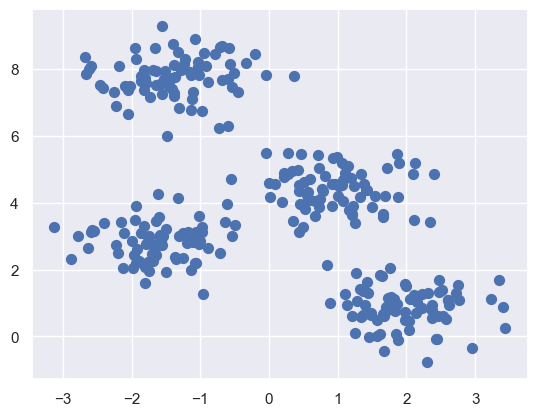

In [2]:
from sklearn.datasets import make_blobs

X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=0)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

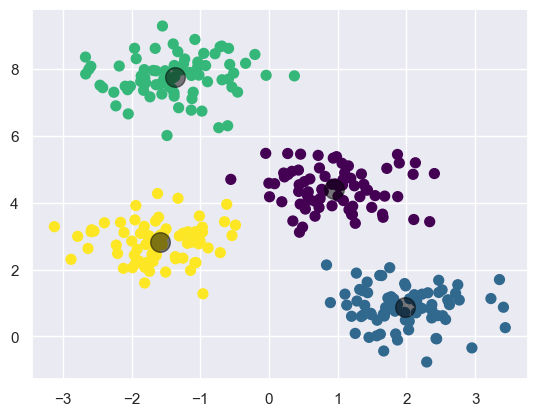

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

### Algoritma Expectation-Maximization (E-M)

Mengimplementasikan fungsi `find_clusters` secara manual yang mengikuti prinsip *Expectation-Maximization*: memilih pusat awal secara acak, menetapkan setiap titik ke pusat terdekat (*E-step*), dan memperbarui pusat klaster dari rata-rata anggotanya (*M-step*) sampai konvergen.

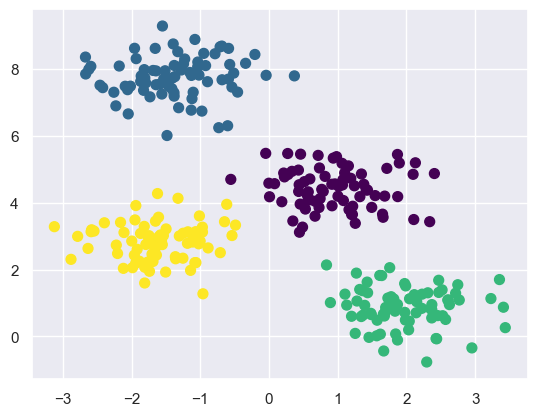

In [5]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]
    
    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)
        
        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])
        
        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers
    
    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

#### Perubahan Random Seed

Mencoba mengubah nilai `rseed=0` untuk melihat bagaimana inisialisasi titik pusat awal yang kurang tepat dapat membuat algoritma E-M terjebak pada konvergensi lokal yang kurang optimal.

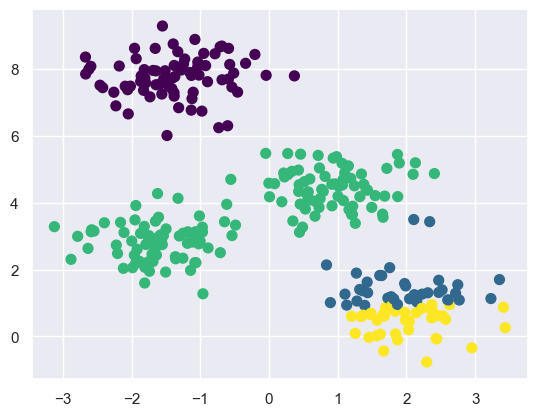

In [6]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

#### Optimalisasi Jumlah Klaster

Mencoba menjalankan K-Means dengan `n_clusters=6` pada data yang sebenarnya hanya terdiri dari 4 klaster.

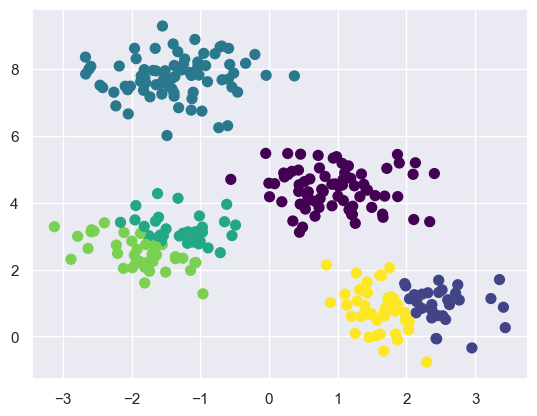

In [7]:
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

#### Batas Klaster yang Tidak Selalu Linier

Menguji K-Means pada dataset berbentuk dua sabit (`make_moons`). Karena K-Means mengandalkan jarak ke titik centroid (batas linier Voronoi), K-Means gagal memisahkan bentuk bulan sabit, sedangkan `SpectralClustering` yang menggunakan graf ketetanggaan terdekat (`affinity='nearest_neighbors'`) berhasil memisahkannya dengan tepat.

In [8]:
from sklearn.datasets import make_moons

X, y = make_moons(200, noise=.05, random_state=0)

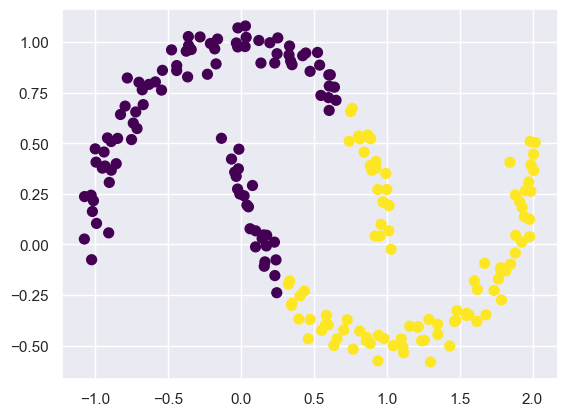

In [9]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

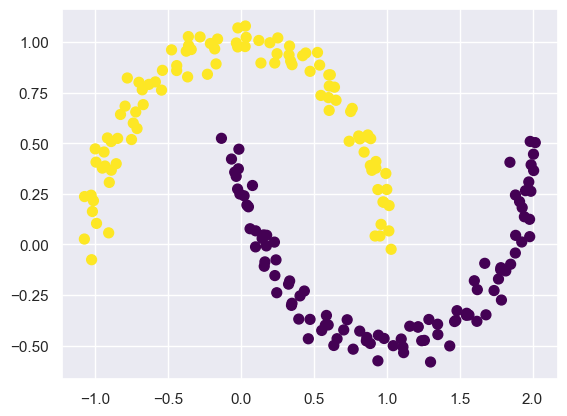

In [10]:
from sklearn.cluster import SpectralClustering

model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans', random_state=0)
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

---

### Contoh Kasus 1: Karakter Angka (`load_digits`)

Menerapkan K-Means (`n_clusters=10`) pada dataset citra angka tulisan tangan berukuran 8x8 piksel (64 fitur) berjumlah 1.797 sampel tanpa melihat label aslinya, lalu membandingkan akurasi sebelum dan sesudah reduksi dimensi non-linier menggunakan `TSNE`.

In [11]:
from sklearn.datasets import load_digits

digits = load_digits()
digits.data.shape

(1797, 64)

In [12]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

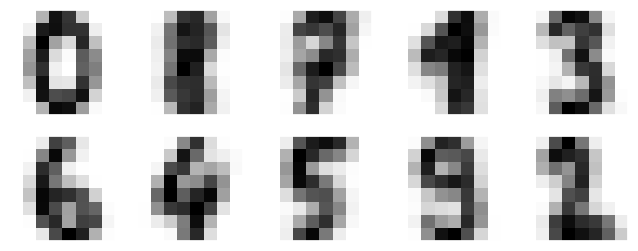

In [13]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [14]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

In [15]:
from sklearn.metrics import accuracy_score

accuracy_score(digits.target, labels)

0.7918753478018921

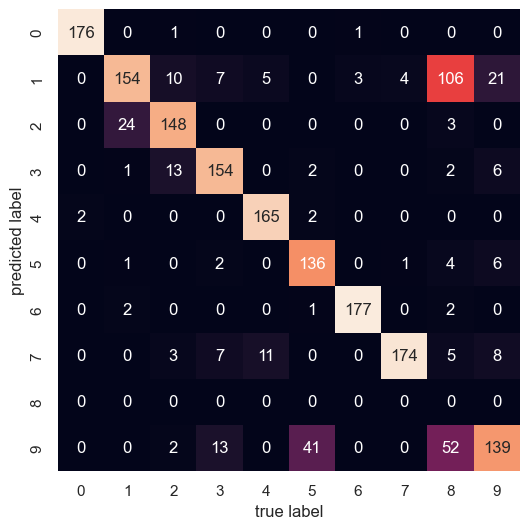

Text(25.078125, 0.5, 'predicted label')

In [16]:
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(digits.target, labels)
plt.figure(figsize=(8, 6))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [17]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9415692821368948

Pada kasus angka tulisan tangan di atas, K-Means langsung pada ruang 64 dimensi sudah mampu mengenali bentuk ke-10 pusat angka dengan akurasi sekitar `79.35%` (beberapa kesalahan terjadi antara angka `1` dan `8` atau `8` dan `9` yang bentuk pikselnya mirip). Namun ketika data diproyeksikan terlebih dahulu ke ruang 2 dimensi menggunakan `TSNE` sebelum diklasterisasi dengan K-Means, akurasinya melonjak tinggi menjadi sekitar `94.16%`.

---

### Studi Kasus 2: Kompresi Citra (`flower.jpg`)

Menggunakan `MiniBatchKMeans` dengan 16 klaster untuk mereduksi jutaan kemungkinan warna RGB pada citra `flower.jpg` (`427 x 640` piksel = `273.280` piksel) menjadi hanya 16 warna representatif (centroid warna).

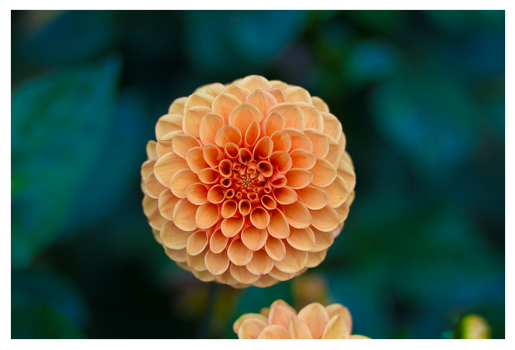

In [18]:
from sklearn.datasets import load_sample_image

flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

In [19]:
flower.shape

(427, 640, 3)

In [20]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

In [21]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data
    
    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

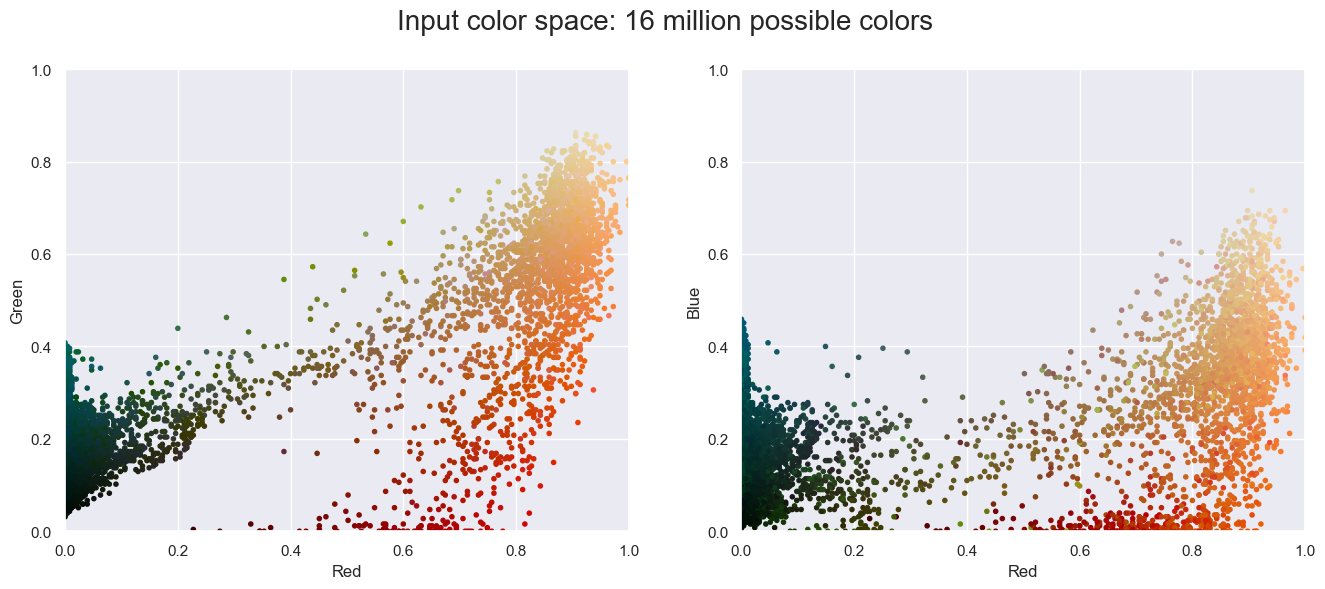

In [22]:
plot_pixels(data, title='Input color space: 16 million possible colors')

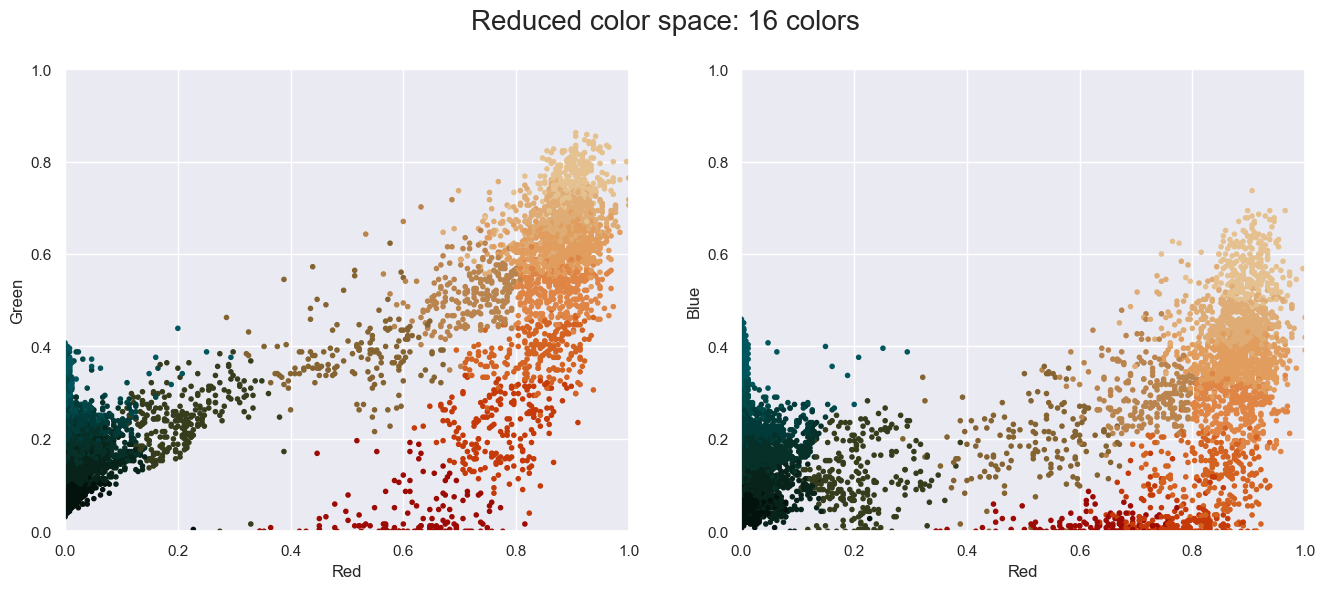

In [23]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16, random_state=0)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")

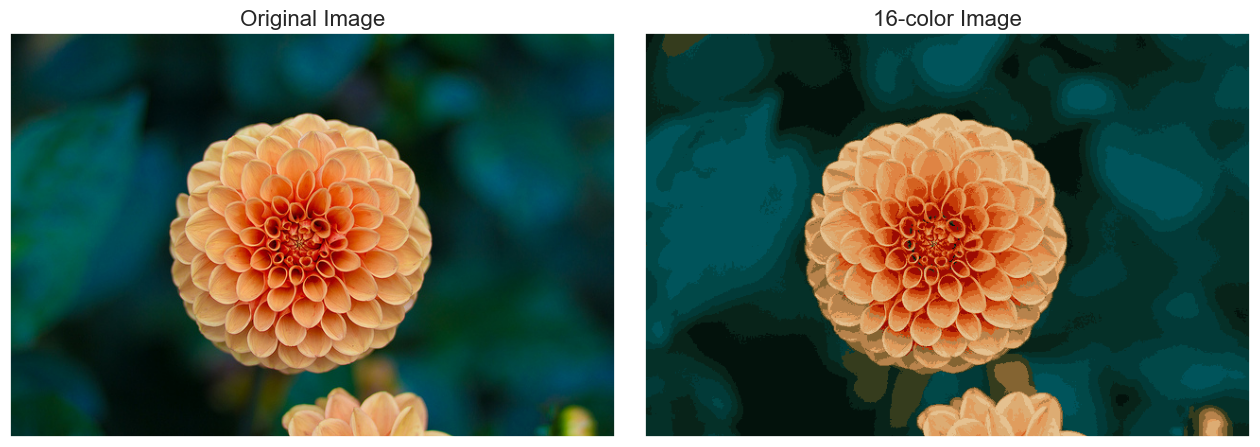

Text(0.5, 1.0, '16-color Image')

In [24]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

Dari hasil perbandingan gambar di atas, meskipun ruang warna gambar dipangkas secara ekstrem dari ~16 juta kemungkinan warna RGB menjadi hanya 16 warna pusat klaster (`16-color Image`), tampilan visual bunga merah dan latar belakang daunnya masih tetap sangat jelas dan dikenali dengan baik.